# Credit Card Customer Behaviour & Portfolio Analysis
**Python | Pandas | NumPy | Matplotlib | Seaborn**

## Project objective
Analyse customer spending, cash-advance behaviour, credit limits, balances, payments and full-payment frequency to identify descriptive patterns that may help a business understand its customer portfolio.


## 1. Import libraries and load the dataset


In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

try:
    import seaborn as sns
    sns.set_theme(style="whitegrid")
except ImportError:
    sns = None

from IPython.display import display

# Try common locations first
candidate_paths = [
    Path("credit_card_customers_cleaned.csv"),
    Path("Downloads") / "DA Project" / "credit_card_customers_cleaned.csv",
    Path.home() / "Downloads" / "DA Project" / "credit_card_customers_cleaned.csv",
]

csv_path = next((p for p in candidate_paths if p.exists()), None)

if csv_path is None:
    try:
        import tkinter as tk
        from tkinter import filedialog
        root = tk.Tk()
        root.withdraw()
        selected = filedialog.askopenfilename(
            title="Select credit_card_customers_cleaned.csv",
            filetypes=[("CSV files", "*.csv")]
        )
        root.destroy()
        if selected:
            csv_path = Path(selected)
    except Exception:
        pass

if csv_path is None or not csv_path.exists():
    raise FileNotFoundError(
        "CSV not found. Put credit_card_customers_cleaned.csv beside this notebook "
        "or select the CSV when prompted."
    )

df = pd.read_csv(csv_path)
print(f"Loaded: {csv_path}")
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")
display(df.head())

Loaded: C:\Users\Kritika Verma\Downloads\DA Project\credit_card_customers_cleaned.csv
Rows: 8,950 | Columns: 20


,customer_id,balance,balance_frequency,purchases,oneoff_purchases,installments_purchases,cash_advance,purchases_frequency,oneoff_purchases_frequency,purchases_installments_frequency,cash_advance_frequency,cash_advance_trx,purchases_trx,credit_limit,payments,minimum_payments_original,minimum_payments_clean,min_payment_status,prc_full_payment,tenure
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,139.509787,Available,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,1072.340217,Available,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,627.284787,Available,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,312.343947,Imputed,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,244.791237,Available,0.000000,12


## 2. Data overview and quality checks

In [3]:
print("Dataset shape:", df.shape)
print("Exact duplicate rows:", df.duplicated().sum())

if "customer_id" in df.columns:
    print("Duplicate customer IDs:", df["customer_id"].duplicated().sum())

quality = pd.DataFrame({
    "data_type": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique(dropna=True)
})
display(quality)

Dataset shape: (8950, 20)
Exact duplicate rows: 0
Duplicate customer IDs: 0


,data_type,missing_count,missing_percent,unique_values
customer_id,str,0,0.0,8950
balance,float64,0,0.0,8871
balance_frequency,float64,0,0.0,43
purchases,float64,0,0.0,6203
oneoff_purchases,float64,0,0.0,4014
installments_purchases,float64,0,0.0,4452
cash_advance,float64,0,0.0,4323
purchases_frequency,float64,0,0.0,47
oneoff_purchases_frequency,float64,0,0.0,47
purchases_installments_frequency,float64,0,0.0,47


## 3. Prepare analysis columns

In [4]:
# Make a working copy; preserve the source dataframe
data = df.copy()

# Convert likely numeric analysis fields safely
numeric_candidates = [
    "balance", "balance_frequency", "purchases", "oneoff_purchases",
    "installments_purchases", "cash_advance", "purchases_frequency",
    "oneoff_purchases_frequency", "purchases_installments_frequency",
    "cash_advance_frequency", "cash_advance_trx", "purchases_trx",
    "credit_limit", "payments", "minimum_payments_original",
    "minimum_payments_clean", "prc_full_payment", "tenure"
]
for col in numeric_candidates:
    if col in data.columns:
        data[col] = pd.to_numeric(data[col], errors="coerce")

# Standardise common categorical text fields, without changing their meaning
if "min_payment_status" in data.columns:
    data["min_payment_status"] = data["min_payment_status"].astype("string").str.strip()

display(data.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customer_id,8950,8950,C10001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
balance,8950.0,NaN,NaN,NaN,1564.474828,2081.531879,0.0,128.281915,873.385231,2054.140036,19043.13856
balance_frequency,8950.0,NaN,NaN,NaN,0.877271,0.236904,0.0,0.888889,1.0,1.0,1.0
purchases,8950.0,NaN,NaN,NaN,1003.204834,2136.634782,0.0,39.635,361.28,1110.13,49039.57
oneoff_purchases,8950.0,NaN,NaN,NaN,592.437371,1659.887917,0.0,0.0,38.0,577.405,40761.25
installments_purchases,8950.0,NaN,NaN,NaN,411.067645,904.338115,0.0,0.0,89.0,468.6375,22500.0
cash_advance,8950.0,NaN,NaN,NaN,978.871112,2097.163877,0.0,0.0,0.0,1113.821139,47137.21176
purchases_frequency,8950.0,NaN,NaN,NaN,0.490351,0.401371,0.0,0.083333,0.5,0.916667,1.0
oneoff_purchases_frequency,8950.0,NaN,NaN,NaN,0.202458,0.298336,0.0,0.0,0.083333,0.3,1.0
purchases_installments_frequency,8950.0,NaN,NaN,NaN,0.364437,0.397448,0.0,0.0,0.166667,0.75,1.0


## 4. Portfolio KPIs

In [5]:
n_customers = len(data)
purchase_users = int((data["purchases"].fillna(0) > 0).sum()) if "purchases" in data else np.nan
cash_users = int((data["cash_advance"].fillna(0) > 0).sum()) if "cash_advance" in data else np.nan

kpis = {
    "Total customers": n_customers,
    "Customers with purchases": purchase_users,
    "Purchase participation (%)": round(purchase_users / n_customers * 100, 2) if n_customers else np.nan,
    "Cash-advance users": cash_users,
    "Cash-advance participation (%)": round(cash_users / n_customers * 100, 2) if n_customers else np.nan,
}
for col, label in [
    ("balance", "Average balance"),
    ("purchases", "Average purchases"),
    ("payments", "Average payments"),
    ("minimum_payments_clean", "Average cleaned minimum payment"),
    ("credit_limit", "Average credit limit")
]:
    if col in data.columns:
        kpis[label] = round(data[col].mean(), 2)

kpi_table = pd.DataFrame({"KPI": list(kpis.keys()), "Value": list(kpis.values())})
display(kpi_table)

,KPI,Value
0,Total customers,8950.00
1,Customers with purchases,6906.00
2,Purchase participation (%),77.16
3,Cash-advance users,4322.00
4,Cash-advance participation (%),48.29
5,Average balance,1564.47
6,Average purchases,1003.20
7,Average payments,1733.14
8,Average cleaned minimum payment,844.91
9,Average credit limit,4494.28


## 5. Purchase behaviour

,purchase_group,customer_count,average_purchases,average_balance,average_payments,customer_percentage
0,Has purchases,6906,1300.13,1390.82,1756.83,77.16
1,No purchases recorded,2044,0.00,2151.20,1653.13,22.84


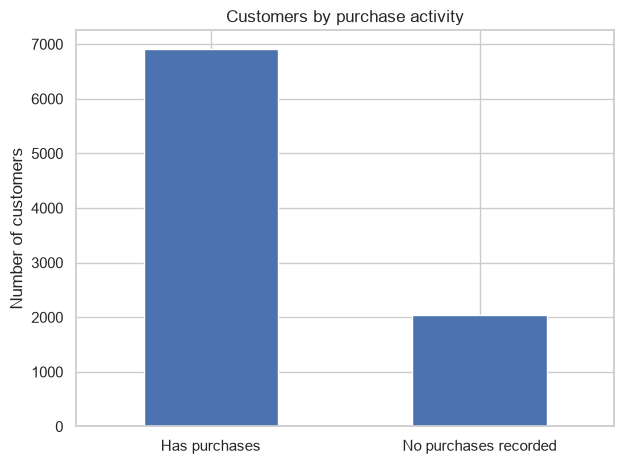

In [6]:
if "purchases" in data.columns:
    data["purchase_group"] = np.where(data["purchases"].fillna(0) > 0, "Has purchases", "No purchases recorded")
    purchase_summary = data.groupby("purchase_group", dropna=False).agg(
        customer_count=("purchase_group", "size"),
        average_purchases=("purchases", "mean"),
        average_balance=("balance", "mean") if "balance" in data else ("purchase_group", "size"),
        average_payments=("payments", "mean") if "payments" in data else ("purchase_group", "size")
    ).reset_index()
    purchase_summary["customer_percentage"] = (purchase_summary["customer_count"] / len(data) * 100).round(2)
    display(purchase_summary.round(2))

    purchase_summary.set_index("purchase_group")["customer_count"].plot(kind="bar", title="Customers by purchase activity")
    plt.ylabel("Number of customers")
    plt.xlabel("")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

## 6. Cash-advance behaviour

,cash_advance_group,customer_count,average_cash_advance,average_purchases,average_balance,average_payments,customer_percentage
0,Cash advance user,4322,2027.05,633.82,2390.86,2054.49,48.29
1,No cash advance,4628,0.00,1348.17,792.73,1433.04,51.71


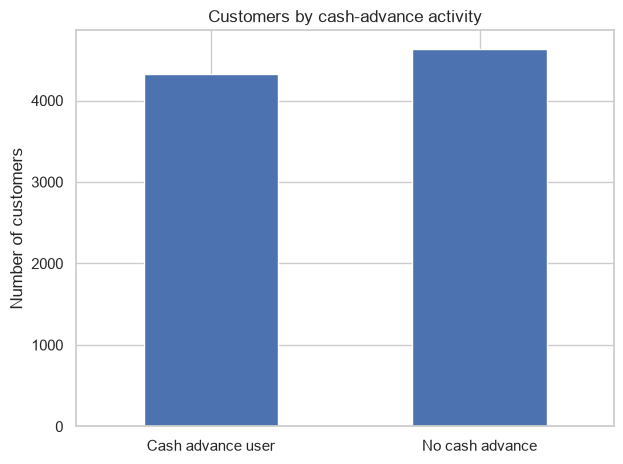

In [7]:
if "cash_advance" in data.columns:
    data["cash_advance_group"] = np.where(data["cash_advance"].fillna(0) > 0, "Cash advance user", "No cash advance")
    cash_summary = data.groupby("cash_advance_group").agg(
        customer_count=("cash_advance_group", "size"),
        average_cash_advance=("cash_advance", "mean"),
        average_purchases=("purchases", "mean") if "purchases" in data else ("cash_advance", "mean"),
        average_balance=("balance", "mean") if "balance" in data else ("cash_advance", "mean"),
        average_payments=("payments", "mean") if "payments" in data else ("cash_advance", "mean")
    ).reset_index()
    cash_summary["customer_percentage"] = (cash_summary["customer_count"] / len(data) * 100).round(2)
    display(cash_summary.round(2))

    cash_summary.set_index("cash_advance_group")["customer_count"].plot(kind="bar", title="Customers by cash-advance activity")
    plt.ylabel("Number of customers")
    plt.xlabel("")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

## 7. Credit-limit segments

,credit_limit_band,customer_count,balance,purchases,payments
0,"Below 2,000",2619,635.02,421.73,761.92
1,"2,000–4,999",3044,1093.87,740.82,1302.86
2,"5,000–9,999",2446,2233.83,1357.16,2317.77
3,"10,000 and above",841,4215.51,2734.24,4614.76


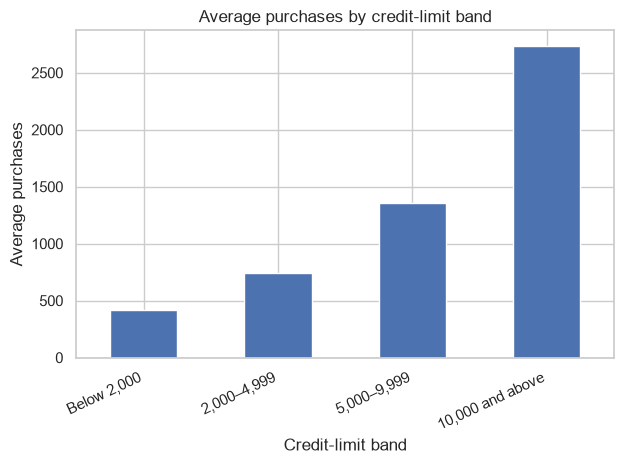

In [8]:
if "credit_limit" in data.columns:
    bins = [-np.inf, 1999.99, 4999.99, 9999.99, np.inf]
    labels = ["Below 2,000", "2,000–4,999", "5,000–9,999", "10,000 and above"]
    data["credit_limit_band"] = pd.cut(data["credit_limit"], bins=bins, labels=labels)
    agg = {"customer_id": "count"} if "customer_id" in data else {}
    for col in ["balance", "purchases", "payments"]:
        if col in data.columns:
            agg[col] = "mean"
    credit_summary = data.groupby("credit_limit_band", observed=False).agg(agg).reset_index()
    credit_summary = credit_summary.rename(columns={"customer_id":"customer_count"})
    display(credit_summary.round(2))

    if "purchases" in data.columns:
        credit_summary.set_index("credit_limit_band")["purchases"].plot(kind="bar", title="Average purchases by credit-limit band")
        plt.ylabel("Average purchases")
        plt.xlabel("Credit-limit band")
        plt.xticks(rotation=25, ha="right")
        plt.tight_layout()
        plt.show()

## 8. Full-payment frequency

In [9]:
if "prc_full_payment" in data.columns:
    data["full_payment_segment"] = pd.cut(
        data["prc_full_payment"],
        bins=[-0.000001, 0, 0.499999, 1.000001],
        labels=["No full payment recorded", "Below 0.50", "0.50 or higher"],
        include_lowest=True
    )
    agg = {"prc_full_payment":"mean"}
    for col in ["payments", "balance", "minimum_payments_clean"]:
        if col in data.columns:
            agg[col] = "mean"
    fullpay_summary = data.groupby("full_payment_segment", observed=False).agg(
        customer_count=("full_payment_segment", "size"),
        **{col: (col, fn) for col, fn in agg.items()}
    ).reset_index()
    display(fullpay_summary.round(2))

,full_payment_segment,customer_count,prc_full_payment,payments,balance,minimum_payments_clean
0,No full payment recorded,5903,0.00,1315.85,2065.01,1089.39
1,Below 0.50,1771,0.19,2769.88,886.14,494.28
2,0.50 or higher,1276,0.82,2224.71,190.40,200.52


## 9. Purchase types and activity frequency

,average_value
purchases,1003.204834
oneoff_purchases,592.437371
installments_purchases,411.067645


,average_frequency
purchases_frequency,0.490351
oneoff_purchases_frequency,0.202458
purchases_installments_frequency,0.364437
cash_advance_frequency,0.135144


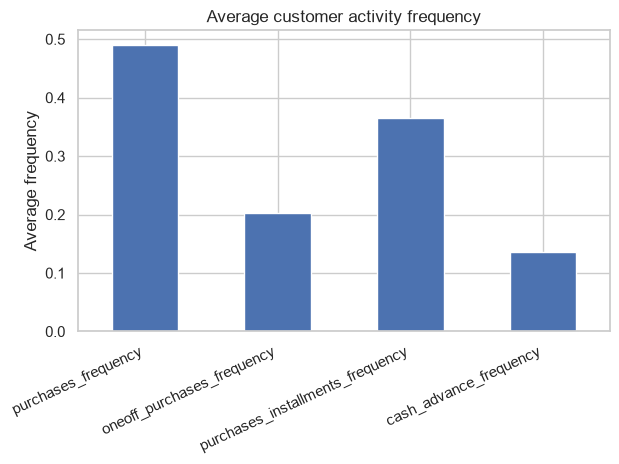

In [10]:
purchase_type_cols = [c for c in ["purchases", "oneoff_purchases", "installments_purchases"] if c in data.columns]
if purchase_type_cols:
    display(data[purchase_type_cols].mean().rename("average_value").to_frame())

frequency_cols = [c for c in [
    "purchases_frequency", "oneoff_purchases_frequency",
    "purchases_installments_frequency", "cash_advance_frequency"
] if c in data.columns]
if frequency_cols:
    display(data[frequency_cols].mean().rename("average_frequency").to_frame())
    data[frequency_cols].mean().plot(kind="bar", title="Average customer activity frequency")
    plt.ylabel("Average frequency")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()

## 10. Correlation analysis

,balance,purchases,oneoff_purchases,installments_purchases,cash_advance,credit_limit,payments,minimum_payments_clean,prc_full_payment,purchases_frequency
balance,1.00,0.18,0.16,0.13,0.50,0.53,0.32,0.40,-0.32,-0.08
purchases,0.18,1.00,0.92,0.68,-0.05,0.36,0.60,0.10,0.18,0.39
oneoff_purchases,0.16,0.92,1.00,0.33,-0.03,0.32,0.57,0.05,0.13,0.26
installments_purchases,0.13,0.68,0.33,1.00,-0.06,0.26,0.38,0.13,0.18,0.44
cash_advance,0.50,-0.05,-0.03,-0.06,1.00,0.30,0.45,0.14,-0.15,-0.22
credit_limit,0.53,0.36,0.32,0.26,0.30,1.00,0.42,0.13,0.06,0.12
payments,0.32,0.60,0.57,0.38,0.45,0.42,1.00,0.13,0.11,0.10
minimum_payments_clean,0.40,0.10,0.05,0.13,0.14,0.13,0.13,1.00,-0.14,0.01
prc_full_payment,-0.32,0.18,0.13,0.18,-0.15,0.06,0.11,-0.14,1.00,0.31
purchases_frequency,-0.08,0.39,0.26,0.44,-0.22,0.12,0.10,0.01,0.31,1.00


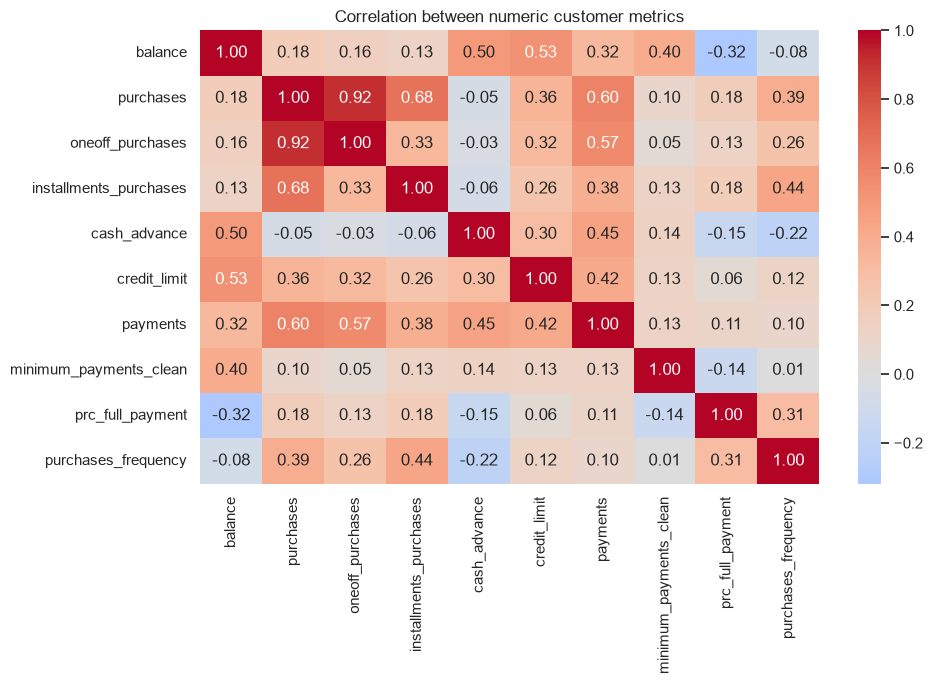

In [11]:
corr_cols = [c for c in [
    "balance", "purchases", "oneoff_purchases", "installments_purchases",
    "cash_advance", "credit_limit", "payments", "minimum_payments_clean",
    "prc_full_payment", "purchases_frequency"
] if c in data.columns]
if len(corr_cols) >= 2:
    corr = data[corr_cols].corr(numeric_only=True)
    display(corr.round(2))
    if sns is not None:
        plt.figure(figsize=(10, 7))
        sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
        plt.title("Correlation between numeric customer metrics")
        plt.tight_layout()
        plt.show()
    else:
        plt.figure(figsize=(10, 7))
        plt.imshow(corr, aspect="auto")
        plt.xticks(range(len(corr.columns)), corr.columns, rotation=45, ha="right")
        plt.yticks(range(len(corr.index)), corr.index)
        plt.colorbar(label="Correlation")
        plt.title("Correlation between numeric customer metrics")
        plt.tight_layout()
        plt.show()

## 11. Outlier review (flag only; do not automatically delete)

In [12]:
outlier_rows = []
for col in ["balance", "purchases", "cash_advance", "payments"]:
    if col in data.columns:
        s = data[col].dropna()
        if len(s):
            q1, q3 = s.quantile([0.25, 0.75])
            iqr = q3 - q1
            lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
            outlier_rows.append({
                "metric": col, "Q1": q1, "Q3": q3, "IQR": iqr,
                "lower_limit": lower, "upper_limit": upper,
                "outlier_count": int(((s < lower) | (s > upper)).sum()),
                "outlier_percent": round(((s < lower) | (s > upper)).mean() * 100, 2)
            })
outlier_summary = pd.DataFrame(outlier_rows)
display(outlier_summary.round(2))

,metric,Q1,Q3,IQR,lower_limit,upper_limit,outlier_count,outlier_percent
0,balance,128.28,2054.14,1925.86,-2760.51,4942.93,695,7.77
1,purchases,39.64,1110.13,1070.50,-1566.11,2715.87,808,9.03
2,cash_advance,0.00,1113.82,1113.82,-1670.73,2784.55,1030,11.51
3,payments,383.28,1901.13,1517.86,-1893.51,4177.92,808,9.03


## 12. Automatically generated key findings

In [13]:
findings = []
if len(data):
    findings.append(f"The dataset contains {len(data):,} customer records.")
if "purchases" in data.columns and len(data):
    p = int((data["purchases"].fillna(0) > 0).sum())
    findings.append(f"{p:,} customers ({p/len(data)*100:.2f}%) recorded purchases.")
if "cash_advance" in data.columns and len(data):
    c = int((data["cash_advance"].fillna(0) > 0).sum())
    findings.append(f"{c:,} customers ({c/len(data)*100:.2f}%) recorded a positive cash advance.")
if "balance" in data.columns and "cash_advance" in data.columns:
    groups = data.assign(cash_advance_group=np.where(data["cash_advance"].fillna(0)>0, "Cash advance user", "No cash advance")).groupby("cash_advance_group")["balance"].mean()
    if "Cash advance user" in groups and "No cash advance" in groups:
        findings.append(f"Average balance: cash-advance users {groups['Cash advance user']:.2f}; non-users {groups['No cash advance']:.2f}. This is descriptive, not causal.")
if "credit_limit" in data.columns and "purchases" in data.columns:
    bands = data.assign(credit_limit_band=pd.cut(data["credit_limit"], [-np.inf,1999.99,4999.99,9999.99,np.inf],
                                               labels=["Below 2,000","2,000–4,999","5,000–9,999","10,000 and above"]))
    band_means = bands.groupby("credit_limit_band", observed=False)["purchases"].mean().dropna()
    if len(band_means) >= 2:
        findings.append("Average purchases differ across credit-limit bands; review the segment summary above before making business decisions.")

for i, finding in enumerate(findings, 1):
    print(f"{i}. {finding}")

1. The dataset contains 8,950 customer records.
2. 6,906 customers (77.16%) recorded purchases.
3. 4,322 customers (48.29%) recorded a positive cash advance.
4. Average balance: cash-advance users 2390.86; non-users 792.73. This is descriptive, not causal.
5. Average purchases differ across credit-limit bands; review the segment summary above before making business decisions.


## 13. Export analysis tables
Saves useful summary tables to a folder called `python_outputs` beside this notebook.

In [14]:
output_dir = Path("python_outputs")
output_dir.mkdir(exist_ok=True)

quality.to_csv(output_dir / "data_quality_report.csv")
kpi_table.to_csv(output_dir / "portfolio_kpis.csv", index=False)

if "purchase_summary" in globals():
    purchase_summary.to_csv(output_dir / "purchase_summary.csv", index=False)
if "cash_summary" in globals():
    cash_summary.to_csv(output_dir / "cash_advance_summary.csv", index=False)
if "credit_summary" in globals():
    credit_summary.to_csv(output_dir / "credit_limit_summary.csv", index=False)
if "fullpay_summary" in globals():
    fullpay_summary.to_csv(output_dir / "full_payment_summary.csv", index=False)
if "outlier_summary" in globals():
    outlier_summary.to_csv(output_dir / "outlier_summary.csv", index=False)

print("Exported summary tables to:", output_dir.resolve())

Exported summary tables to: C:\Users\Kritika Verma\Downloads\python_outputs


## 14. Conclusion and limitations

Use the actual outputs from the cells above to write the final business conclusion. Discuss:
- purchase participation and customers with no recorded purchases;
- cash-advance usage and how balances differ between groups;
- how average purchases and balances vary by credit-limit band;
- payment-frequency patterns and data-quality concerns;
- possible business actions, such as further investigation of low-engagement segments.

**Limitations:** this dataset is observational; field definitions and time period may be limited; outliers may be genuine customers; average payments are not necessarily payments for the same period as purchases; and the analysis does not establish causation or predict defaults.